# Telco Customer Churn - Exploratory Analysis, Statistical Testing and Predictive Modelling

## B.Tech Data Analytics (CES2103) mini-project, Manipal Institute of Technology, MAHE.

**Team Number:** Team_02

### Team Members:
* LAVANYA SANDEEP BORKAR - 251090050708
* TANVI CHOUDHARY - 251090052750
* GAURI NIKHIL CHANDAK - 251090051220 


**Pre-declared protocol (fixed before any model was fitted):**
1. `TotalCharges` -> numeric; the 11 blank values are replaced by 0 (all have `tenure = 0`, i.e. customers not yet billed).
2. `customerID` is excluded from modelling.
3. "No internet service" / "No phone service" are kept as their own categories and one-hot encoded like any other level.
4. Stratified 80:20 train/test split, `random_state = 42`. All preprocessing is fitted on training data only (inside a scikit-learn `Pipeline`, so also only on the training folds during cross-validation).
5. Models: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting; class weighting is treated as a hyper-parameter where supported.
6. Model comparison and tuning use 5-fold stratified cross-validation **on the training set only**. The held-out test set is used once, after the final model is chosen.
7. Selection rule (declared in advance): highest mean CV ROC-AUC; models within one standard error of the best are treated as tied and the most interpretable of them is preferred.
8. EDA and hypothesis tests use the full dataset descriptively; no modelling decision (feature selection, encoding, hyper-parameters) is based on them.

**Scope note.** The submitted report (`report/Team_02.pdf`) is built on Sections 1-4 of this notebook (data verification, exploratory data analysis, and the chi-square test of Contract x Churn with its effect size). Sections 5-9 (train/test split, cross-validated predictive models, held-out evaluation and interpretation) are an additional, supplementary analysis that goes beyond the report. The statistical tests in the report describe associations only; they do not establish causes.


In [1]:
import json
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import scipy
import sklearn
from scipy import stats

SEED = 42
np.random.seed(SEED)

BASE = Path.cwd()
FIG, TAB = BASE / "figures", BASE / "tables"
FIG.mkdir(exist_ok=True)
TAB.mkdir(exist_ok=True)

FNAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
CANDIDATES = [BASE / "data" / FNAME, BASE / FNAME, BASE.parent / FNAME]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, f"Put {FNAME} in the data/ folder next to this notebook."

# ---- figure style (validated categorical palette; one hue family per meaning) ----
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
C_RET, C_CHURN = C_BLUE, C_ORANGE          # retained = blue, churned = orange (in every figure)
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "lines.linewidth": 1.8,
})
DIVERGING = LinearSegmentedColormap.from_list("div", [C_BLUE, "#f0efec", C_RED])
SEQ_BLUE = LinearSegmentedColormap.from_list("seq", [SURF, "#9ec5f4", "#256abf", "#0d366b"])


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()


def save_table(frame, name, index=False):
    frame.to_csv(TAB / f"{name}.csv", index=index)
    return frame


print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("Data file:", DATA_PATH.name, "|", DATA_PATH.stat().st_size, "bytes")
with open(BASE / "requirements.txt", "w") as fh:
    fh.write(f"# versions used for the reported run (Python {platform.python_version()})\n"
             f"numpy=={np.__version__}\npandas=={pd.__version__}\nscipy=={scipy.__version__}\n"
             f"scikit-learn=={sklearn.__version__}\nmatplotlib=={matplotlib.__version__}\n")

Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | scipy 1.18.0 | scikit-learn 1.9.0 | matplotlib 3.11.0
Data file: WA_Fn-UseC_-Telco-Customer-Churn.csv | 977501 bytes


In [2]:
%matplotlib inline

## 1. Data loading and verification

In [3]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)      # everything as text: nothing hidden by type inference
df = pd.read_csv(DATA_PATH)                                          # default typing, as a user would load it
print("Shape:", df.shape)
dtypes = pd.DataFrame({"column": df.columns, "pandas_dtype": [str(t) for t in df.dtypes],
                       "n_unique": [df[c].nunique() for c in df.columns],
                       "example": [df[c].iloc[0] for c in df.columns]})
save_table(dtypes, "column_dtypes")

Shape: (7043, 21)


,column,pandas_dtype,n_unique,example
0,customerID,str,7043,7590-VHVEG
1,gender,str,2,Female
2,SeniorCitizen,int64,2,0
3,Partner,str,2,Yes
4,Dependents,str,2,No
5,tenure,int64,73,1
6,PhoneService,str,2,No
7,MultipleLines,str,3,No phone service
8,InternetService,str,3,DSL
9,OnlineSecurity,str,3,No


In [4]:
s = df["TotalCharges"].astype(str).str.strip()
blank_mask = s.eq("")
tc_numeric = pd.to_numeric(s.where(~blank_mask), errors="coerce")
assert tc_numeric.isna().sum() == blank_mask.sum(), "non-blank TotalCharges values failed to parse"

print("TotalCharges loaded as:", df["TotalCharges"].dtype)
print("Blank TotalCharges cells:", int(blank_mask.sum()))
print("...of which tenure == 0 :", int((df.loc[blank_mask, "tenure"] == 0).sum()))
print("Rows with tenure == 0   :", int((df["tenure"] == 0).sum()))
print("Churn among blank rows  :", df.loc[blank_mask, "Churn"].value_counts().to_dict())
blank_rows = save_table(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "Contract", "Churn"]],
                        "totalcharges_blank_rows")
blank_rows

TotalCharges loaded as: str
Blank TotalCharges cells: 11
...of which tenure == 0 : 11
Rows with tenure == 0   : 11
Churn among blank rows  : {'No': 11}


,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


**Rationale for the imputation.** All blank `TotalCharges` rows are exactly the rows with `tenure = 0`:
these customers have not completed a billing month, so their cumulative charge is genuinely zero rather than "unknown".
Replacing by 0 is therefore a domain-justified value (not a mean/median guess), keeps all 7,043 customers, and, because the
value is determined by `tenure`, it carries no information about the target (none of these 11 churned).

In [5]:
df["TotalCharges"] = tc_numeric.fillna(0.0)
df["y"] = (df["Churn"] == "Yes").astype(int)            # positive class = churn

expected = {"gender": {"Female", "Male"}, "Partner": {"Yes", "No"}, "Dependents": {"Yes", "No"},
            "PhoneService": {"Yes", "No"}, "PaperlessBilling": {"Yes", "No"}, "Churn": {"Yes", "No"},
            "Contract": {"Month-to-month", "One year", "Two year"},
            "InternetService": {"DSL", "Fiber optic", "No"}}
unexpected = {c: sorted(set(df[c]) - v) for c, v in expected.items() if set(df[c]) - v}
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_net = df["InternetService"] == "No"
checks = [
    ("Rows", len(df)), ("Columns (incl. ID and target)", df.shape[1]),
    ("NaN cells (default parse)", int(pd.read_csv(DATA_PATH).isna().sum().sum())),
    ("Blank-string cells (raw text), all columns", int(raw.apply(lambda c: c.str.strip().eq("")).sum().sum())),
    ("Blank TotalCharges cells", int(blank_mask.sum())),
    ("Duplicate rows (all columns)", int(raw.duplicated().sum())),
    ("Duplicate customerID", int(df["customerID"].duplicated().sum())),
    ("Rows identical when customerID is ignored", int(raw.drop(columns="customerID").duplicated().sum())),
    ("Negative tenure / MonthlyCharges / TotalCharges", int((df[["tenure", "MonthlyCharges", "TotalCharges"]] < 0).sum().sum())),
    ("Unexpected category labels", int(sum(len(v) for v in unexpected.values()))),
    ("PhoneService=No but MultipleLines != 'No phone service'", int(((df.PhoneService == "No") & (df.MultipleLines != "No phone service")).sum())),
    ("InternetService=No but an add-on != 'No internet service'", int(sum((no_net & (df[a] != "No internet service")).sum() for a in addons))),
    ("tenure in [0,72]", bool(df.tenure.between(0, 72).all())),
]
quality = save_table(pd.DataFrame(checks, columns=["check", "result"]), "data_quality_checks")
quality

,check,result
0,Rows,7043
1,Columns (incl. ID and target),22
2,NaN cells (default parse),0
3,"Blank-string cells (raw text), all columns",11
4,Blank TotalCharges cells,11
5,Duplicate rows (all columns),0
6,Duplicate customerID,0
7,Rows identical when customerID is ignored,22
8,Negative tenure / MonthlyCharges / TotalCharges,0
9,Unexpected category labels,0


## 2. Target distribution and feature summaries

In [6]:
vc = df["Churn"].value_counts()
target = pd.DataFrame({"class": ["No (retained)", "Yes (churned)"], "count": [int(vc["No"]), int(vc["Yes"])]})
target["percent"] = (target["count"] / len(df) * 100).round(2)
save_table(target, "churn_distribution")
print(target.to_string(index=False))
print(f"Imbalance ratio (retained : churned) = {vc['No'] / vc['Yes']:.2f} : 1")

NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
numeric_summary = df[NUM].describe().T
numeric_summary["skew"] = df[NUM].skew()
numeric_summary = numeric_summary.round(3)
save_table(numeric_summary.reset_index().rename(columns={"index": "feature"}), "numeric_summary")
by_churn = df.groupby("Churn")[NUM].agg(["mean", "median", "std"]).round(2)
save_table(by_churn.reset_index(), "numeric_by_churn")
print(numeric_summary.to_string())
by_churn

        class  count  percent
No (retained)   5174    73.46
Yes (churned)   1869    26.54
Imbalance ratio (retained : churned) = 2.77 : 1
                 count      mean       std    min     25%      50%      75%      max   skew
tenure          7043.0    32.371    24.559   0.00    9.00    29.00    55.00    72.00  0.240
MonthlyCharges  7043.0    64.762    30.090  18.25   35.50    70.35    89.85   118.75 -0.221
TotalCharges    7043.0  2279.734  2266.794   0.00  398.55  1394.55  3786.60  8684.80  0.963


tenure               MonthlyCharges               TotalCharges           \
        mean median    std           mean median    std         mean   median   
Churn                                                                           
No     37.57   38.0  24.11          61.27  64.43  31.09      2549.91  1679.52   
Yes    17.98   10.0  19.53          74.44  79.65  24.67      1531.80   703.55   

                
           std  
Churn           
No     2329.95  
Yes    1890.82

In [7]:
CAT_FEATURES = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
                "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
rows = []
for c in CAT_FEATURES:
    g = df.groupby(c)["y"].agg(["size", "sum"])
    for lvl, r in g.iterrows():
        rows.append({"feature": c, "level": str(lvl), "n": int(r["size"]),
                     "pct_of_customers": round(r["size"] / len(df) * 100, 2),
                     "churned": int(r["sum"]), "churn_rate_pct": round(r["sum"] / r["size"] * 100, 2)})
cat_summary = save_table(pd.DataFrame(rows), "categorical_churn_rates")
print("Overall churn rate: %.2f%%" % (df.y.mean() * 100))
cat_summary

Overall churn rate: 26.54%


,feature,level,n,pct_of_customers,churned,churn_rate_pct
0,gender,Female,3488,49.52,939,26.92
1,gender,Male,3555,50.48,930,26.16
2,SeniorCitizen,0,5901,83.79,1393,23.61
3,SeniorCitizen,1,1142,16.21,476,41.68
4,Partner,No,3641,51.70,1200,32.96
5,Partner,Yes,3402,48.30,669,19.66
6,Dependents,No,4933,70.04,1543,31.28
7,Dependents,Yes,2110,29.96,326,15.45
8,PhoneService,No,682,9.68,170,24.93
9,PhoneService,Yes,6361,90.32,1699,26.71


## 3. Exploratory data analysis (figures)

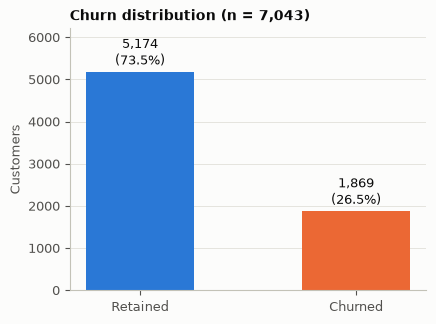

In [8]:
fig, ax = plt.subplots(figsize=(4.6, 3.4))
vals = [vc["No"], vc["Yes"]]
ax.bar(["Retained", "Churned"], vals, color=[C_RET, C_CHURN], width=0.5)
for i, v in enumerate(vals):
    ax.text(i, v + 80, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, max(vals) * 1.2)
ax.set_ylabel("Customers")
ax.set_title("Churn distribution (n = 7,043)")
save_fig(fig, "fig01_churn_distribution")

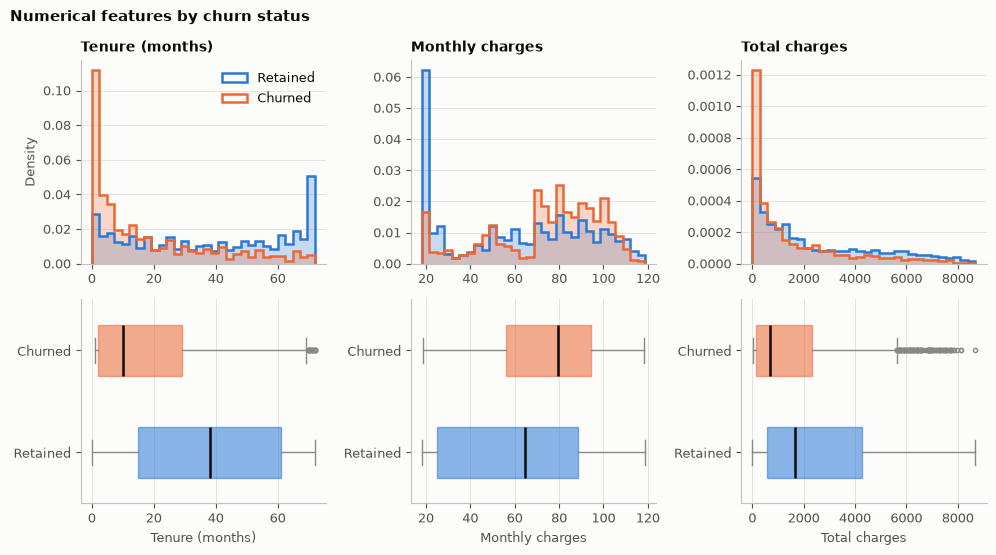

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
labels = {"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges", "TotalCharges": "Total charges"}
for j, c in enumerate(NUM):
    ax = axes[0, j]
    bins = np.linspace(df[c].min(), df[c].max(), 31)
    for flag, colr, name in [(0, C_RET, "Retained"), (1, C_CHURN, "Churned")]:
        d = df.loc[df.y == flag, c]
        ax.hist(d, bins=bins, density=True, histtype="stepfilled", color=colr, alpha=0.25, linewidth=0)
        ax.hist(d, bins=bins, density=True, histtype="step", color=colr, linewidth=1.8, label=name)
    ax.set_title(labels[c]); ax.set_ylabel("Density" if j == 0 else "")
    if j == 0:
        ax.legend(loc="upper right")
    bx = axes[1, j]
    data = [df.loc[df.y == 0, c], df.loc[df.y == 1, c]]
    bp = bx.boxplot(data, orientation="horizontal", widths=0.5, patch_artist=True, tick_labels=["Retained", "Churned"],
                    medianprops={"color": INK, "linewidth": 1.8}, whiskerprops={"color": MUTED},
                    capprops={"color": MUTED}, flierprops={"markeredgecolor": MUTED, "markersize": 3})
    for patch, colr in zip(bp["boxes"], [C_RET, C_CHURN]):
        patch.set_facecolor(colr); patch.set_alpha(0.55); patch.set_edgecolor(colr)
    bx.set_xlabel(labels[c]); bx.grid(axis="x"); bx.grid(axis="y", visible=False)
fig.suptitle("Numerical features by churn status", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig02_numeric_distributions")

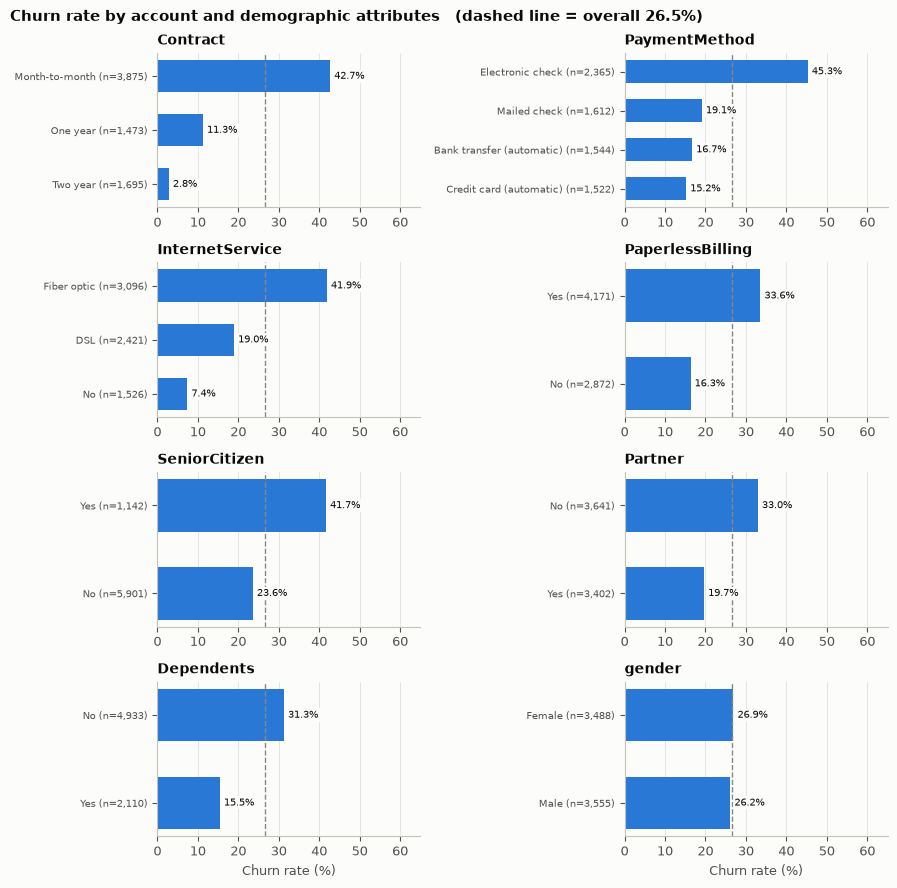

In [10]:
overall = df.y.mean() * 100


def rate_panel(ax, col, order=None):
    g = df.groupby(col)["y"].agg(["mean", "size"])
    if col == "SeniorCitizen":
        g.index = g.index.map({0: "No", 1: "Yes"})
    g = g.loc[order] if order else g.sort_values("mean")
    ax.barh(range(len(g)), g["mean"] * 100, color=C_BLUE, height=0.6)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"{i} (n={n:,})" for i, n in zip(g.index, g["size"])], fontsize=7.5)
    for i, v in enumerate(g["mean"] * 100):
        ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=7.5, zorder=5,
                bbox={"facecolor": SURF, "edgecolor": "none", "pad": 1.0})
    ax.axvline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xlim(0, 65); ax.set_title(col)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)


def rate_figure(cols, name, title):
    fig, axes = plt.subplots(len(cols) // 2, 2, figsize=(9, 2.1 * (len(cols) // 2) + 0.6))
    for ax, c in zip(axes.ravel(), cols):
        rate_panel(ax, c)
    for ax in axes[-1]:
        ax.set_xlabel("Churn rate (%)")
    fig.suptitle(title + f"   (dashed line = overall {overall:.1f}%)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_fig(fig, name)


rate_figure(["Contract", "PaymentMethod", "InternetService", "PaperlessBilling",
             "SeniorCitizen", "Partner", "Dependents", "gender"],
            "fig03_churn_rate_account_demographics", "Churn rate by account and demographic attributes")

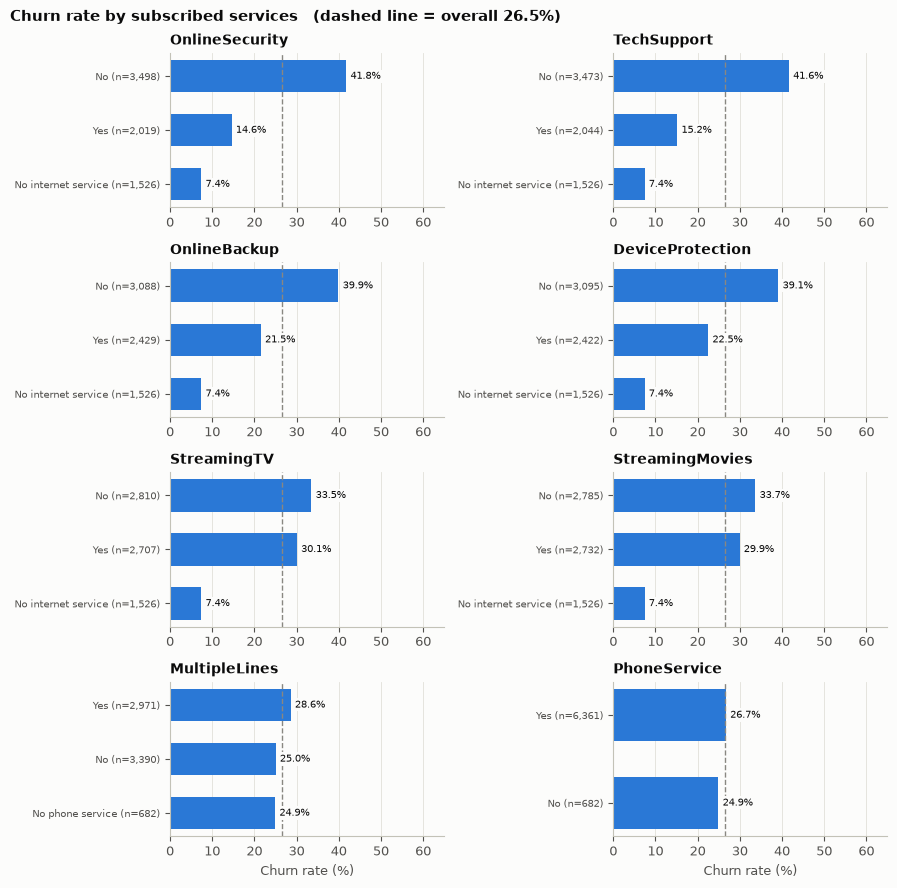

In [11]:
rate_figure(["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
             "StreamingTV", "StreamingMovies", "MultipleLines", "PhoneService"],
            "fig04_churn_rate_services", "Churn rate by subscribed services")

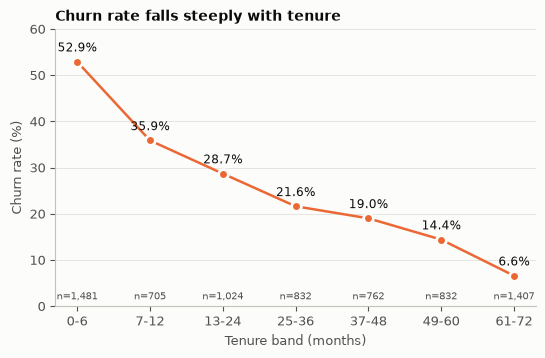

In [12]:
bins = [-1, 6, 12, 24, 36, 48, 60, 72]
names = ["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
df["tenure_band"] = pd.cut(df["tenure"], bins=bins, labels=names)
tb = df.groupby("tenure_band", observed=True)["y"].agg(["mean", "size"]).reset_index()
tb["churn_rate_pct"] = (tb["mean"] * 100).round(2)
save_table(tb.drop(columns="mean").rename(columns={"size": "n"}), "churn_by_tenure_band")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(range(len(tb)), tb["mean"] * 100, color=C_CHURN, marker="o", markersize=7,
        markeredgecolor=SURF, markeredgewidth=2)
for i, (r, n) in enumerate(zip(tb["mean"] * 100, tb["size"])):
    ax.text(i, r + 2.2, f"{r:.1f}%", ha="center", fontsize=8.5)
    ax.text(i, 1.5, f"n={n:,}", ha="center", fontsize=7.5, color=INK2)
ax.set_xticks(range(len(tb))); ax.set_xticklabels(tb["tenure_band"])
ax.set_ylim(0, 60); ax.set_xlabel("Tenure band (months)"); ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate falls steeply with tenure")
save_fig(fig, "fig05_churn_by_tenure_band")

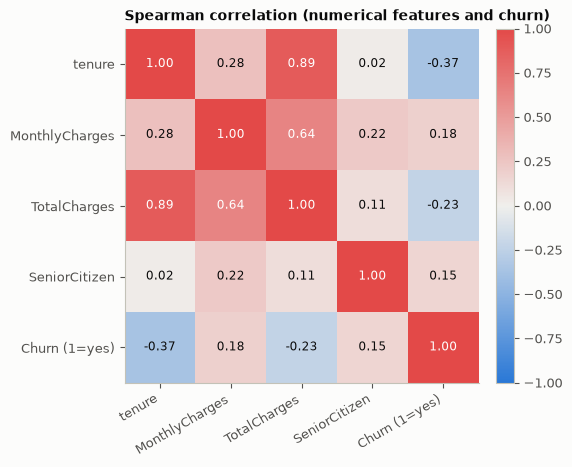

                tenure  MonthlyCharges  TotalCharges  SeniorCitizen  Churn (1=yes)
tenure           1.000           0.276         0.890          0.019         -0.367
MonthlyCharges   0.276           1.000         0.638          0.221          0.185
TotalCharges     0.890           0.638         1.000          0.108         -0.230
SeniorCitizen    0.019           0.221         0.108          1.000          0.151
Churn (1=yes)   -0.367           0.185        -0.230          0.151          1.000


In [13]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "y"]
corr = df[corr_cols].corr(method="spearman")
corr.index = corr.columns = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn (1=yes)"]
save_table(corr.round(3).reset_index().rename(columns={"index": "feature"}), "spearman_correlation")
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else INK)
ax.grid(False); ax.set_title("Spearman correlation (numerical features and churn)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
save_fig(fig, "fig06_spearman_heatmap")
print(corr.round(3).to_string())

## 4. Statistical tests

* **Categorical features vs churn:** Pearson chi-square test of independence (16 tests). Effect size = Cramer's V. Multiple testing: Benjamini-Hochberg false-discovery-rate (q) and Bonferroni, both reported.
* **Numerical features vs churn:** two-sided Mann-Whitney U test (3 tests; Holm correction). Effect size = rank-biserial correlation r = 2U/(n1*n2) - 1 (positive = churned customers tend to have larger values).
* With n = 7,043 almost any association is "significant", so **effect sizes are what should be read**. These tests describe association only and do not establish causes.

In [14]:
rows = []
for c in CAT_FEATURES:
    ct = pd.crosstab(df[c], df["Churn"])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n, k = ct.values.sum(), min(ct.shape) - 1
    rows.append({"feature": c, "levels": ct.shape[0], "chi2": chi2, "dof": dof, "p_value": p,
                 "cramers_v": float(np.sqrt(chi2 / (n * k))), "min_expected_count": float(exp.min())})
chi = pd.DataFrame(rows)
m = len(chi)
chi["p_bonferroni"] = np.minimum(chi["p_value"] * m, 1.0)
chi["q_value_BH"] = stats.false_discovery_control(chi["p_value"].values, method="bh")
chi["significant_BH_0.05"] = chi["q_value_BH"] < 0.05
chi["significant_Bonferroni_0.05"] = chi["p_bonferroni"] < 0.05
chi = chi.sort_values("cramers_v", ascending=False).reset_index(drop=True)
save_table(chi, "chi_square_results")
print("All expected counts >= 5:", bool((chi["min_expected_count"] >= 5).all()))
print("Significant after BH (q<0.05):", int(chi["significant_BH_0.05"].sum()), "of", m,
      "| after Bonferroni:", int(chi["significant_Bonferroni_0.05"].sum()), "of", m)
chi.assign(p_value=chi.p_value.map("{:.2e}".format), p_bonferroni=chi.p_bonferroni.map("{:.2e}".format),
           q_value_BH=chi.q_value_BH.map("{:.2e}".format)).round(4)

All expected counts >= 5: True
Significant after BH (q<0.05): 14 of 16 | after Bonferroni: 13 of 16


,feature,levels,chi2,dof,p_value,cramers_v,min_expected_count,p_bonferroni,q_value_BH,significant_BH_0.05,significant_Bonferroni_0.05
0,Contract,3,1184.5966,2,5.86e-258,0.4101,390.8898,9.38e-257,9.38e-257,True,True
1,OnlineSecurity,3,849.9990,2,2.66e-185,0.3474,404.9544,4.26e-184,2.13e-184,True,True
2,TechSupport,3,828.1971,2,1.44e-180,0.3429,404.9544,2.31e-179,7.70e-180,True,True
3,InternetService,3,732.3096,2,9.57e-160,0.3225,404.9544,1.53e-158,3.83e-159,True,True
4,PaymentMethod,4,648.1423,3,3.68e-140,0.3034,403.8929,5.89e-139,1.18e-139,True,True
5,OnlineBackup,3,601.8128,2,2.08e-131,0.2923,404.9544,3.33e-130,5.55e-131,True,True
6,DeviceProtection,3,558.4194,2,5.51e-122,0.2816,404.9544,8.81e-121,1.26e-121,True,True
7,StreamingMovies,3,375.6615,2,2.67e-82,0.2310,404.9544,4.27e-81,5.34e-82,True,True
8,StreamingTV,3,374.2039,2,5.53e-82,0.2305,404.9544,8.85e-81,9.83e-82,True,True
9,PaperlessBilling,2,258.2776,1,4.07e-58,0.1915,762.1423,6.52e-57,6.52e-58,True,True


In [15]:
rows = []
for c in NUM:
    a, b = df.loc[df.y == 1, c], df.loc[df.y == 0, c]
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": c, "median_churned": a.median(), "median_retained": b.median(),
                 "IQR_churned": a.quantile(.75) - a.quantile(.25), "IQR_retained": b.quantile(.75) - b.quantile(.25),
                 "U": U, "p_value": p, "rank_biserial_r": 2 * U / (len(a) * len(b)) - 1})
mw = pd.DataFrame(rows)
order = np.argsort(mw["p_value"].values)                    # Holm step-down
holm = np.empty(len(mw)); running = 0.0
for rank, i in enumerate(order):
    running = max(running, min((len(mw) - rank) * mw["p_value"].values[i], 1.0)); holm[i] = running
mw["p_holm"] = holm
mw["significant_Holm_0.05"] = mw["p_holm"] < 0.05
save_table(mw, "mann_whitney_results")
mw.assign(p_value=mw.p_value.map("{:.2e}".format), p_holm=mw.p_holm.map("{:.2e}".format)).round(3)

,feature,median_churned,median_retained,IQR_churned,IQR_retained,U,p_value,rank_biserial_r,p_holm,significant_Holm_0.05
0,tenure,10.00,38.000,27.00,46.00,2515538.0,2.42e-208,-0.480,7.26e-208,True
1,MonthlyCharges,79.65,64.425,38.05,63.30,6003125.5,3.31e-54,0.242,3.31e-54,True
2,TotalCharges,703.55,1679.525,2196.80,3689.95,3381224.0,5.69e-83,-0.301,1.14e-82,True


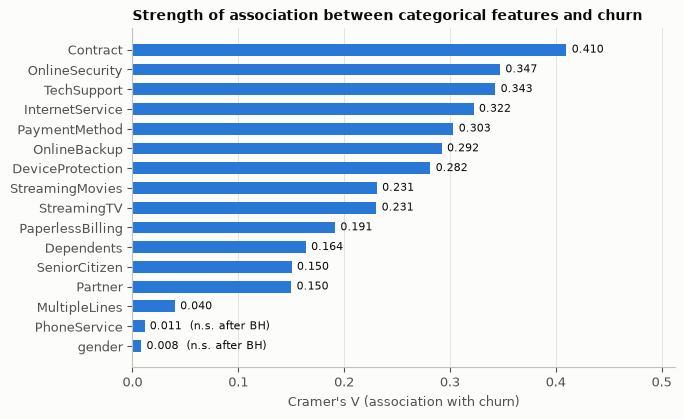

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.4))
cs = chi.sort_values("cramers_v")
ax.barh(cs["feature"], cs["cramers_v"], color=C_BLUE, height=0.6)
for i, (v, sig) in enumerate(zip(cs["cramers_v"], cs["significant_BH_0.05"])):
    ax.text(v + 0.005, i, f"{v:.3f}" + ("" if sig else "  (n.s. after BH)"), va="center", fontsize=8)
ax.set_xlim(0, cs["cramers_v"].max() * 1.25); ax.set_xlabel("Cramer's V (association with churn)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Strength of association between categorical features and churn")
save_fig(fig, "fig07_cramers_v")

## 5. Train/test split and preprocessing

In [17]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             make_scorer, brier_score_loss)
from sklearn.inspection import permutation_importance, partial_dependence

X = df.drop(columns=["customerID", "Churn", "y", "tenure_band"])
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
split = pd.DataFrame({"set": ["train", "test"], "rows": [len(X_train), len(X_test)],
                      "churned": [int(y_train.sum()), int(y_test.sum())],
                      "churn_pct": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]})
save_table(split, "train_test_split")
print(split.to_string(index=False))
print("customerID in model features:", "customerID" in X.columns, "| n features:", X.shape[1])

NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
BIN_COLS = ["SeniorCitizen"]
CAT_COLS = [c for c in X.columns if c not in NUM_COLS + BIN_COLS]
print("categorical columns one-hot encoded:", len(CAT_COLS))


def make_pre():
    """Preprocessing fitted only on whatever data the surrounding Pipeline is fitted on (training data)."""
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("bin", "passthrough", BIN_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), CAT_COLS),
    ], verbose_feature_names_out=False)


class GBWithClassWeight(ClassifierMixin, BaseEstimator):
    """GradientBoostingClassifier has no class_weight argument, so the equivalent per-sample weights are applied in fit()."""

    def __init__(self, class_weight=None, n_estimators=100, learning_rate=0.1, max_depth=3,
                 subsample=0.8, random_state=SEED):
        self.class_weight = class_weight
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.subsample = subsample
        self.random_state = random_state

    def fit(self, X, y):
        sw = compute_sample_weight(self.class_weight, y) if self.class_weight else None
        self.model_ = GradientBoostingClassifier(
            n_estimators=self.n_estimators, learning_rate=self.learning_rate, max_depth=self.max_depth,
            subsample=self.subsample, random_state=self.random_state).fit(X, y, sample_weight=sw)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


def make_pipe(est):
    return Pipeline([("pre", make_pre()), ("clf", est)])


Z = make_pre().fit_transform(X_train)
print("Design matrix after encoding (fit on training data only):", Z.shape)

  set  rows  churned  churn_pct
train  5634     1495      26.54
 test  1409      374      26.54
customerID in model features: False | n features: 19
categorical columns one-hot encoded: 15
Design matrix after encoding (fit on training data only): (5634, 40)


## 6. Model comparison by 5-fold stratified cross-validation (training data only)

**Stage A** compares all four model families with fixed, reasonable hyper-parameters, with and without class weighting, plus a majority-class baseline.
**Stage B** tunes each family with a small grid (class weighting is one of the tuned options) using ROC-AUC as the refit criterion.
Positive class = churn. Precision/recall/F1 are for the churn class at the default 0.5 probability threshold.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
METRICS = list(SCORING)

stage_a = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    "Logistic Regression (balanced)": LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    "Decision Tree (balanced)": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", random_state=SEED),
    "Gradient Boosting": GBWithClassWeight(n_estimators=200, learning_rate=0.05, max_depth=3),
    "Gradient Boosting (balanced)": GBWithClassWeight(class_weight="balanced", n_estimators=200, learning_rate=0.05, max_depth=3),
}
rows, t0 = [], time.time()
for name, est in stage_a.items():
    r = cross_validate(make_pipe(est), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=2)
    row = {"model": name}
    for k in METRICS:
        row[k] = r[f"test_{k}"].mean()
        row[k + "_sd"] = r[f"test_{k}"].std()
    rows.append(row)
    print(f"{name:34s} AUC={row['roc_auc']:.4f}  F1={row['f1']:.4f}  recall={row['recall']:.4f}")
stage_a_df = pd.DataFrame(rows)
save_table(stage_a_df.round(4), "cv_stageA_fixed_hyperparameters")
print(f"Stage A took {time.time() - t0:.0f}s")
stage_a_df[["model"] + METRICS].round(4)

Baseline (majority class)          AUC=0.5000  F1=0.0000  recall=0.0000
Logistic Regression                AUC=0.8462  F1=0.5932  recall=0.5445
Logistic Regression (balanced)     AUC=0.8460  F1=0.6293  recall=0.8027
Decision Tree                      AUC=0.8275  F1=0.5656  recall=0.5137
Decision Tree (balanced)           AUC=0.8287  F1=0.6161  recall=0.7773
Random Forest                      AUC=0.8445  F1=0.5737  recall=0.5037
Random Forest (balanced)           AUC=0.8445  F1=0.6318  recall=0.7271
Gradient Boosting                  AUC=0.8493  F1=0.5923  recall=0.5338
Gradient Boosting (balanced)       AUC=0.8485  F1=0.6319  recall=0.7860
Stage A took 24s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (majority class),0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
1,Logistic Regression,0.8023,0.6530,0.5445,0.5932,0.8462,0.6615
2,Logistic Regression (balanced),0.7492,0.5178,0.8027,0.6293,0.8460,0.6600
3,Decision Tree,0.7916,0.6345,0.5137,0.5656,0.8275,0.6146
4,Decision Tree (balanced),0.7432,0.5109,0.7773,0.6161,0.8287,0.6133
5,Random Forest,0.8014,0.6678,0.5037,0.5737,0.8445,0.6570
6,Random Forest (balanced),0.7755,0.5589,0.7271,0.6318,0.8445,0.6555
7,Gradient Boosting,0.8053,0.6663,0.5338,0.5923,0.8493,0.6690
8,Gradient Boosting (balanced),0.7572,0.5286,0.7860,0.6319,0.8485,0.6664


In [19]:
search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=SEED), {
        "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {
        "clf__max_depth": [3, 4, 5, 6, 8], "clf__min_samples_leaf": [10, 25, 50],
        "clf__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=SEED), {
        "clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [3, 5, 10],
        "clf__class_weight": [None, "balanced_subsample"]}),
    "Gradient Boosting": (GBWithClassWeight(), {
        "clf__n_estimators": [100, 200], "clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3],
        "clf__class_weight": [None, "balanced"]}),
}
tuned, grid_tables, t0 = {}, [], time.time()
for name, (est, grid) in search_space.items():
    gs = GridSearchCV(make_pipe(est), grid, scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=2)
    gs.fit(X_train, y_train)
    i = gs.best_index_
    res = {"model": name, "best_params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
           "n_configs": len(gs.cv_results_["params"]), "estimator": gs.best_estimator_}
    for k in METRICS:
        res[k] = gs.cv_results_[f"mean_test_{k}"][i]
        res[k + "_sd"] = gs.cv_results_[f"std_test_{k}"][i]
    tuned[name] = res
    g = pd.DataFrame(gs.cv_results_)
    g.insert(0, "model", name)
    grid_tables.append(g[["model", "params"] + [f"mean_test_{k}" for k in METRICS] + ["rank_test_roc_auc"]])
    print(f"{name:20s} configs={res['n_configs']:3d}  best={res['best_params']}  CV AUC={res['roc_auc']:.4f}")
print(f"Stage B took {time.time() - t0:.0f}s")
save_table(pd.concat(grid_tables).astype({"params": str}).round(4), "cv_stageB_all_grid_results")
stage_b = pd.DataFrame([{**{k: v for k, v in r.items() if k not in ("estimator", "best_params")},
                         "best_params": str(r["best_params"])} for r in tuned.values()])
save_table(stage_b.round(4), "cv_stageB_tuned_models")
stage_b[["model", "best_params"] + METRICS].round(4)

Logistic Regression  configs= 14  best={'C': 3, 'class_weight': None}  CV AUC=0.8464
Decision Tree        configs= 30  best={'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 50}  CV AUC=0.8314
Random Forest        configs= 18  best={'class_weight': None, 'max_depth': 6, 'min_samples_leaf': 5}  CV AUC=0.8478
Gradient Boosting    configs= 16  best={'class_weight': None, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}  CV AUC=0.8506
Stage B took 145s


,model,best_params,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,"{'C': 3, 'class_weight': None}",0.8033,0.6550,0.5472,0.5956,0.8464,0.6616
1,Decision Tree,"{'class_weight': 'balanced', 'max_depth': 6, '...",0.7416,0.5090,0.7980,0.6213,0.8314,0.6280
2,Random Forest,"{'class_weight': None, 'max_depth': 6, 'min_sa...",0.8001,0.6810,0.4676,0.5539,0.8478,0.6612
3,Gradient Boosting,"{'class_weight': None, 'learning_rate': 0.03, ...",0.8071,0.6755,0.5251,0.5907,0.8506,0.6713


## 7. Model selection (rule declared in advance) and decision threshold

In [20]:
INTERPRETABILITY = {"Logistic Regression": 0, "Decision Tree": 1, "Gradient Boosting": 2, "Random Forest": 2}
best_name = max(tuned, key=lambda k: tuned[k]["roc_auc"])
se_best = tuned[best_name]["roc_auc_sd"] / np.sqrt(cv.get_n_splits())
threshold_auc = tuned[best_name]["roc_auc"] - se_best
tied = [k for k in tuned if tuned[k]["roc_auc"] >= threshold_auc]
selected = sorted(tied, key=lambda k: (INTERPRETABILITY[k], -tuned[k]["roc_auc"]))[0]

sel_table = stage_b[["model", "roc_auc", "roc_auc_sd"]].copy()
sel_table["se"] = sel_table["roc_auc_sd"] / np.sqrt(cv.get_n_splits())
sel_table["within_1SE_of_best"] = sel_table["model"].isin(tied)
sel_table["selected"] = sel_table["model"] == selected
save_table(sel_table.round(4), "model_selection")
print(f"Best CV ROC-AUC : {best_name} ({tuned[best_name]['roc_auc']:.4f}, SE {se_best:.4f}) -> tie threshold {threshold_auc:.4f}")
print("Within 1 SE     :", tied)
print("SELECTED MODEL  :", selected, tuned[selected]["best_params"])
sel_table.round(4)

Best CV ROC-AUC : Gradient Boosting (0.8506, SE 0.0054) -> tie threshold 0.8452
Within 1 SE     : ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
SELECTED MODEL  : Logistic Regression {'C': 3, 'class_weight': None}


,model,roc_auc,roc_auc_sd,se,within_1SE_of_best,selected
0,Logistic Regression,0.8464,0.0128,0.0057,True,True
1,Decision Tree,0.8314,0.0133,0.0059,False,False
2,Random Forest,0.8478,0.0099,0.0044,True,False
3,Gradient Boosting,0.8506,0.0121,0.0054,True,False


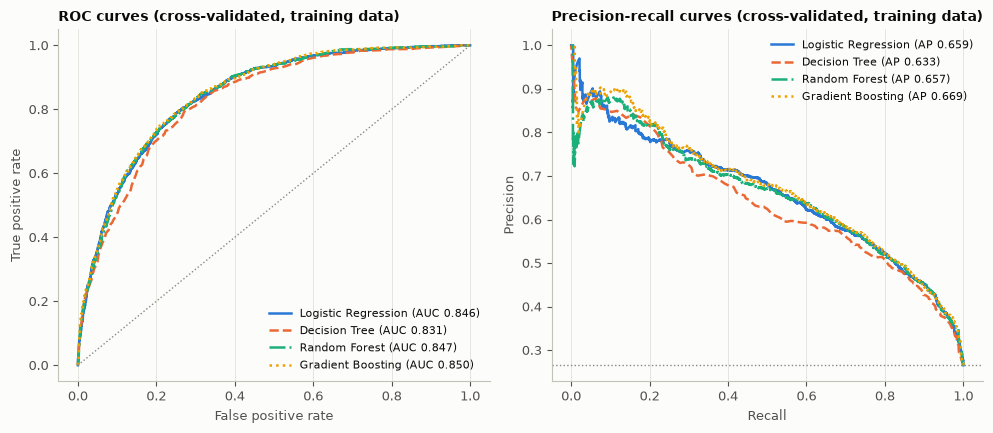

In [21]:
oof = {}
for name in tuned:
    oof[name] = cross_val_predict(clone(tuned[name]["estimator"]), X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=2)[:, 1]
STYLE = {"Logistic Regression": (C_BLUE, "-"), "Decision Tree": (C_ORANGE, "--"),
         "Random Forest": (C_AQUA, "-."), "Gradient Boosting": (C_YELLOW, ":")}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for name, p in oof.items():
    colr, ls = STYLE[name]
    fpr, tpr, _ = roc_curve(y_train, p)
    axes[0].plot(fpr, tpr, color=colr, linestyle=ls, label=f"{name} (AUC {roc_auc_score(y_train, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_train, p)
    axes[1].plot(rc, pr, color=colr, linestyle=ls, label=f"{name} (AP {average_precision_score(y_train, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
axes[1].axhline(y_train.mean(), color=MUTED, linestyle=":", linewidth=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (cross-validated, training data)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (cross-validated, training data)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8); ax.grid(axis="both")
fig.tight_layout()
save_fig(fig, "fig08_cv_roc_pr_curves")

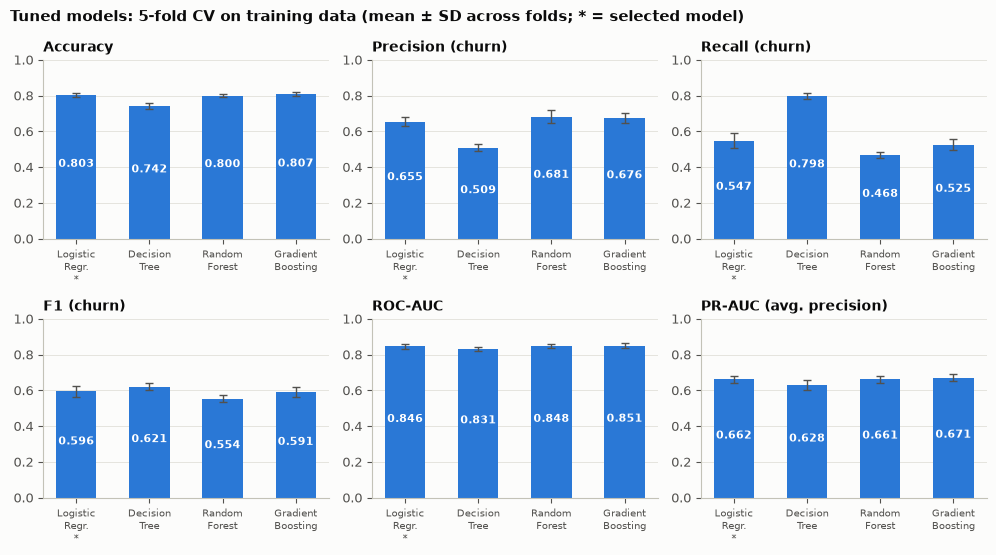

In [22]:
metric_names = {"accuracy": "Accuracy", "precision": "Precision (churn)", "recall": "Recall (churn)",
                "f1": "F1 (churn)", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC (avg. precision)"}
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
short = {"Logistic Regression": "Logistic\nRegr.", "Decision Tree": "Decision\nTree",
         "Random Forest": "Random\nForest", "Gradient Boosting": "Gradient\nBoosting"}
for ax, k in zip(axes.ravel(), METRICS):
    vals = [tuned[n][k] for n in tuned]
    sds = [tuned[n][k + "_sd"] for n in tuned]
    ax.bar(range(4), vals, yerr=sds, color=C_BLUE, width=0.55, error_kw={"ecolor": INK2, "capsize": 3, "linewidth": 1})
    for i, v in enumerate(vals):
        ax.text(i, v / 2, f"{v:.3f}", ha="center", color="white", fontsize=8, fontweight="bold")
    ax.set_xticks(range(4))
    ax.set_xticklabels([short[n] + ("\n*" if n == selected else "") for n in tuned], fontsize=7.5)
    ax.set_ylim(0, 1); ax.set_title(metric_names[k])
fig.suptitle("Tuned models: 5-fold CV on training data (mean ± SD across folds; * = selected model)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig09_cv_metric_comparison")

F1-optimal threshold on out-of-fold training predictions (Logistic Regression): 0.33
 threshold  precision  recall    f1
      0.30      0.542   0.771 0.637
      0.33      0.560   0.741 0.638
      0.40      0.594   0.664 0.627
      0.50      0.655   0.547 0.596


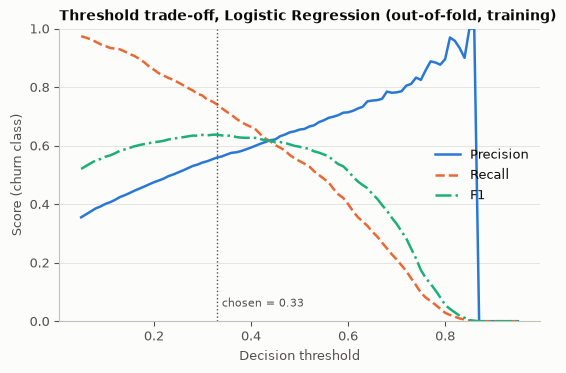

In [23]:
p_sel = oof[selected]
thr_grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame({"threshold": thr_grid,
                      "precision": [precision_score(y_train, p_sel >= t, zero_division=0) for t in thr_grid],
                      "recall": [recall_score(y_train, p_sel >= t) for t in thr_grid],
                      "f1": [f1_score(y_train, p_sel >= t) for t in thr_grid]})
THRESH = float(curve.loc[curve["f1"].idxmax(), "threshold"])      # chosen on training out-of-fold predictions only
save_table(curve.round(4), "threshold_curve_oof_training")
print(f"F1-optimal threshold on out-of-fold training predictions ({selected}): {THRESH:.2f}")
print(curve[curve.threshold.isin([0.30, 0.40, 0.50, THRESH])].drop_duplicates().round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.2, 3.8))
for col, colr, ls in [("precision", C_BLUE, "-"), ("recall", C_ORANGE, "--"), ("f1", C_AQUA, "-.")]:
    ax.plot(curve["threshold"], curve[col], color=colr, linestyle=ls, label=col.capitalize() if col != "f1" else "F1")
ax.axvline(THRESH, color=INK2, linewidth=1, linestyle=":")
ax.text(THRESH + 0.01, 0.05, f"chosen = {THRESH:.2f}", fontsize=8, color=INK2)
ax.set(xlabel="Decision threshold", ylabel="Score (churn class)", ylim=(0, 1),
       title=f"Threshold trade-off, {selected} (out-of-fold, training)")
ax.legend(loc="center right")
save_fig(fig, "fig10_threshold_tradeoff")

## 8. Final evaluation on the held-out test set (used once)

In [24]:
assert "TEST_EVAL_DONE" not in globals(), "the test set must be evaluated only once"
TEST_EVAL_DONE = True
final = tuned[selected]["estimator"]                    # already refitted on the full training set by GridSearchCV
p_test = final.predict_proba(X_test)[:, 1]


def metrics_at(yt, p, thr):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(yt, pred), "precision": precision_score(yt, pred, zero_division=0),
            "recall": recall_score(yt, pred), "f1": f1_score(yt, pred),
            "roc_auc": roc_auc_score(yt, p), "pr_auc": average_precision_score(yt, p)}


test_rows = []
for label, thr in [("default threshold 0.50", 0.5), (f"tuned threshold {THRESH:.2f}", THRESH)]:
    test_rows.append({"model": selected, "operating_point": label, "threshold": thr, **metrics_at(y_test, p_test, thr)})
test_metrics = pd.DataFrame(test_rows)
test_metrics["brier_score"] = brier_score_loss(y_test, p_test)
save_table(test_metrics.round(4), "test_metrics")
ref = pd.DataFrame([{"reference": "majority-class accuracy on test set", "value": 1 - y_test.mean()},
                    {"reference": "churn prevalence on test set (= PR-AUC of a random scorer)", "value": y_test.mean()}])
save_table(ref.round(4), "test_reference_values")
print(test_metrics.round(4).to_string(index=False))
print(ref.round(4).to_string(index=False))

              model        operating_point  threshold  accuracy  precision  recall     f1  roc_auc  pr_auc  brier_score
Logistic Regression default threshold 0.50       0.50    0.8077     0.6614  0.5642 0.6089   0.8419  0.6305       0.1382
Logistic Regression   tuned threshold 0.33       0.33    0.7601     0.5359  0.7193 0.6142   0.8419  0.6305       0.1382
                                                 reference  value
                       majority-class accuracy on test set 0.7346
churn prevalence on test set (= PR-AUC of a random scorer) 0.2654


In [25]:
B = 1000
rng = np.random.default_rng(SEED)
yt, n_t = y_test.values, len(y_test)
boot = {("0.50", k): [] for k in METRICS}
boot.update({(f"{THRESH:.2f}", k): [] for k in METRICS})
for _ in range(B):
    idx = rng.integers(0, n_t, n_t)
    if yt[idx].min() == yt[idx].max():
        continue
    for lab, thr in [("0.50", 0.5), (f"{THRESH:.2f}", THRESH)]:
        for k, v in metrics_at(yt[idx], p_test[idx], thr).items():
            boot[(lab, k)].append(v)
ci = pd.DataFrame([{"threshold": lab, "metric": k, "estimate": metrics_at(yt, p_test, float(lab))[k],
                    "ci_low_2.5%": np.percentile(v, 2.5), "ci_high_97.5%": np.percentile(v, 97.5)}
                   for (lab, k), v in boot.items()])
save_table(ci.round(4), "test_metrics_bootstrap_ci")
print(f"{B} bootstrap resamples of the test set (percentile 95% intervals)")
ci.round(4)

1000 bootstrap resamples of the test set (percentile 95% intervals)


,threshold,metric,estimate,ci_low_2.5%,ci_high_97.5%
0,0.50,accuracy,0.8077,0.7878,0.8290
1,0.50,precision,0.6614,0.6074,0.7076
2,0.50,recall,0.5642,0.5119,0.6145
3,0.50,f1,0.6089,0.5618,0.6492
4,0.50,roc_auc,0.8419,0.8190,0.8625
5,0.50,pr_auc,0.6305,0.5789,0.6829
6,0.33,accuracy,0.7601,0.7374,0.7814
7,0.33,precision,0.5359,0.4906,0.5769
8,0.33,recall,0.7193,0.6736,0.7627
9,0.33,f1,0.6142,0.5724,0.6492


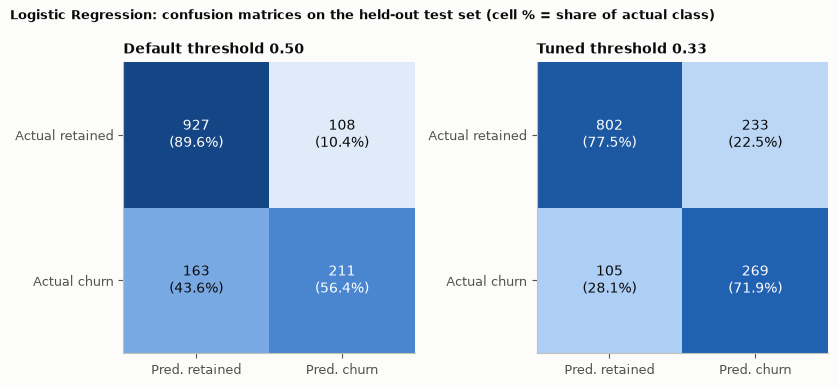

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.9))
for ax, (label, thr) in zip(axes, [("Default threshold 0.50", 0.5), (f"Tuned threshold {THRESH:.2f}", THRESH)]):
    cm = confusion_matrix(y_test, (p_test >= thr).astype(int))
    rowpct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(rowpct, cmap=SEQ_BLUE, vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({rowpct[i, j]:.1f}%)", ha="center", va="center", fontsize=10,
                    color="white" if rowpct[i, j] > 50 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred. retained", "Pred. churn"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual retained", "Actual churn"]); ax.grid(False)
    ax.set_title(label)
    save_table(pd.DataFrame(cm, index=["actual_retained", "actual_churn"], columns=["pred_retained", "pred_churn"]),
               "confusion_matrix_" + ("default_0.50" if thr == 0.5 else "tuned"), index=True)
fig.suptitle(f"{selected}: confusion matrices on the held-out test set (cell % = share of actual class)",
             x=0.01, ha="left", fontweight="bold", fontsize=9.5)
fig.tight_layout()
save_fig(fig, "fig11_test_confusion_matrices")

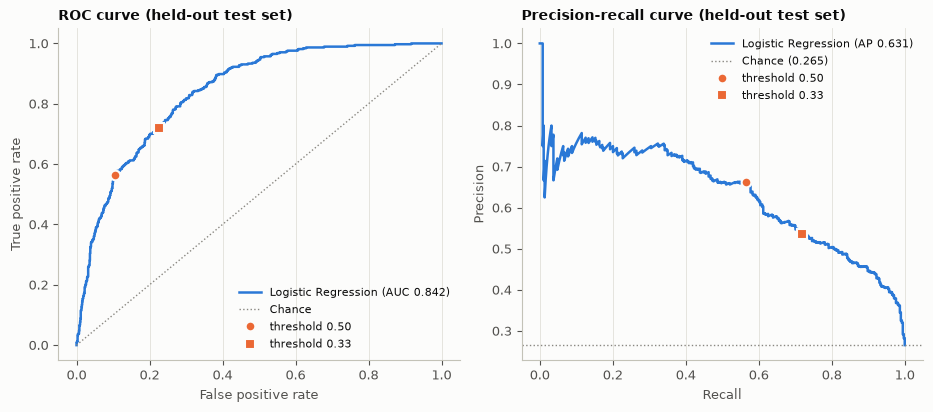

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=C_BLUE, label=f"{selected} (AUC {roc_auc_score(y_test, p_test):.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1, label="Chance")
pr, rc, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rc, pr, color=C_BLUE, label=f"{selected} (AP {average_precision_score(y_test, p_test):.3f})")
axes[1].axhline(y_test.mean(), color=MUTED, linestyle=":", linewidth=1, label=f"Chance ({y_test.mean():.3f})")
for thr, mk, nm in [(0.5, "o", "threshold 0.50"), (THRESH, "s", f"threshold {THRESH:.2f}")]:
    pred = (p_test >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    axes[0].plot(fp / (fp + tn), tp / (tp + fn), mk, color=C_ORANGE, markersize=7, markeredgecolor=SURF,
                 markeredgewidth=1.5, label=nm)
    axes[1].plot(tp / (tp + fn), tp / (tp + fp), mk, color=C_ORANGE, markersize=7, markeredgecolor=SURF,
                 markeredgewidth=1.5, label=nm)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (held-out test set)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (held-out test set)")
axes[0].legend(loc="lower right", fontsize=8); axes[1].legend(loc="upper right", fontsize=8)
for ax in axes:
    ax.grid(axis="both")
fig.tight_layout()
save_fig(fig, "fig12_test_roc_pr_curves")

## 9. Interpretation (association, not causation)

* **Permutation importance** (selected model, held-out test set, ROC-AUC drop when one raw feature is shuffled) shows which inputs the fitted model relies on predictively.
* **Logistic-regression companion**: odds ratios with bootstrap intervals from an L2-regularised logistic regression (tuned C from Stage B) give a directional, human-readable view, whichever model was selected.
* **Partial dependence** shows the selected model's average predicted probability as one numeric input varies.
* None of these identify causes: they describe patterns in observational data, and correlated features (e.g. `tenure`, `MonthlyCharges`, `TotalCharges`) share credit.

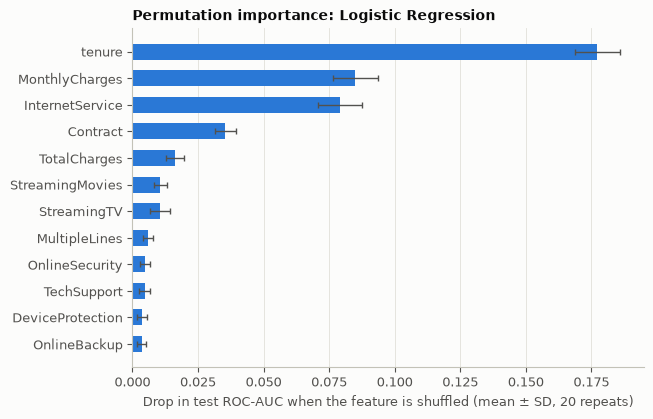

In [28]:
pi = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=2)
imp = pd.DataFrame({"feature": X_test.columns, "auc_drop_mean": pi.importances_mean,
                    "auc_drop_sd": pi.importances_std}).sort_values("auc_drop_mean", ascending=False)
save_table(imp.round(5), "permutation_importance")
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.barh(top["feature"], top["auc_drop_mean"], xerr=top["auc_drop_sd"], color=C_BLUE, height=0.6,
        error_kw={"ecolor": INK2, "capsize": 2.5, "linewidth": 1})
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled (mean ± SD, 20 repeats)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"Permutation importance: {selected}")
save_fig(fig, "fig13_permutation_importance")
imp.head(12).round(4)

LR companion hyper-parameters: {'C': 3, 'class_weight': None} | numeric ORs are per +1 SD of the training data
Perfectly collinear 'No internet service' indicators: 7


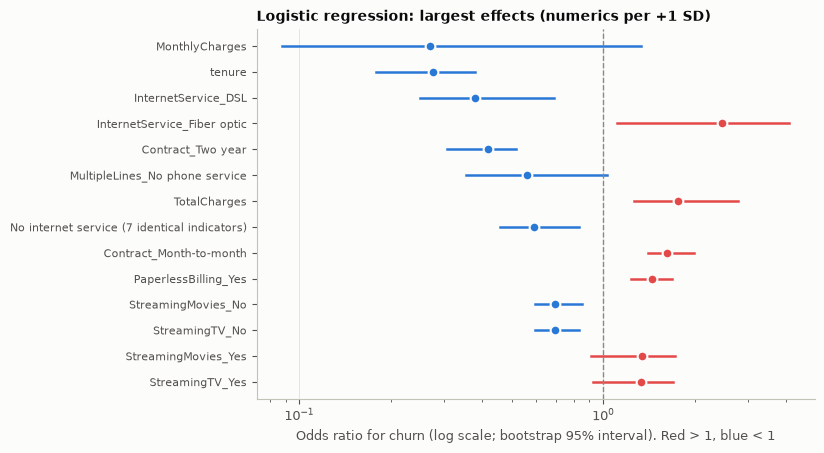

In [29]:
lr_params = tuned["Logistic Regression"]["best_params"]
pre_fit = make_pre().fit(X_train)
Ztr = pre_fit.transform(X_train)
feat_names = pre_fit.get_feature_names_out()
lr_kw = dict(C=lr_params["C"], class_weight=lr_params["class_weight"], max_iter=2000, random_state=SEED)
lr_full = LogisticRegression(**lr_kw).fit(Ztr, y_train)
rng = np.random.default_rng(SEED)
boots = []
for _ in range(300):
    idx = rng.integers(0, len(y_train), len(y_train))
    boots.append(LogisticRegression(**lr_kw).fit(Ztr[idx], y_train.values[idx]).coef_[0])
boots = np.array(boots)
orr = pd.DataFrame({"feature": feat_names, "coef": lr_full.coef_[0], "odds_ratio": np.exp(lr_full.coef_[0]),
                    "or_ci_low": np.exp(np.percentile(boots, 2.5, axis=0)),
                    "or_ci_high": np.exp(np.percentile(boots, 97.5, axis=0))})
orr["abs_coef"] = orr["coef"].abs()
orr = orr.sort_values("abs_coef", ascending=False).drop(columns="abs_coef").reset_index(drop=True)
save_table(orr.round(4), "logistic_regression_odds_ratios")
print("LR companion hyper-parameters:", lr_params, "| numeric ORs are per +1 SD of the training data")
# "No internet service" appears in 6 add-on columns AND as InternetService_No: these 7 indicators are identical
# (perfectly collinear), so the regulariser splits one effect across them. Show them as ONE row in the figure
# (the full table keeps every coefficient).
collinear = [f for f in orr["feature"] if f.endswith("_No internet service") or f == "InternetService_No"]
print("Perfectly collinear 'No internet service' indicators:", len(collinear))
merged = orr[orr["feature"] == "InternetService_No"].copy()
merged["feature"] = f"No internet service ({len(collinear)} identical indicators)"
plot_df = pd.concat([orr[~orr["feature"].isin(collinear)], merged]).assign(a=lambda d: d["coef"].abs())
plot_df = plot_df.sort_values("a", ascending=False)
shown = plot_df.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for i, r in enumerate(shown.itertuples()):
    colr = C_RED if r.odds_ratio > 1 else C_BLUE
    ax.plot([r.or_ci_low, r.or_ci_high], [i, i], color=colr, linewidth=1.8)
    ax.plot(r.odds_ratio, i, "o", color=colr, markersize=7, markeredgecolor=SURF, markeredgewidth=1.5)
ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
ax.set_xscale("log"); ax.set_yticks(range(len(shown))); ax.set_yticklabels(shown["feature"], fontsize=8)
ax.set_xlabel("Odds ratio for churn (log scale; bootstrap 95% interval). Red > 1, blue < 1")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Logistic regression: largest effects (numerics per +1 SD)")
save_fig(fig, "fig14_logistic_odds_ratios")
plot_df.drop(columns="a").head(14).round(3)

       feature  VIF
        tenure 5.93
MonthlyCharges 3.23
  TotalCharges 9.68


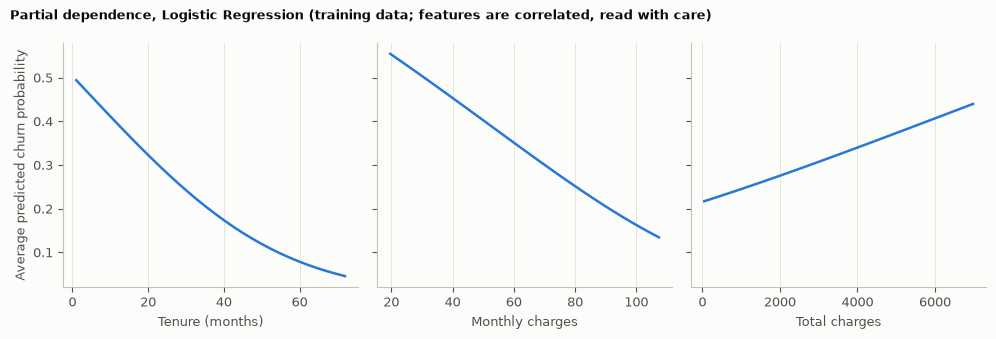

In [30]:
Xn = StandardScaler().fit_transform(X_train[NUM_COLS])
vif = pd.DataFrame({"feature": NUM_COLS, "VIF": [
    1 / (1 - LinearRegression().fit(np.delete(Xn, j, 1), Xn[:, j]).score(np.delete(Xn, j, 1), Xn[:, j]))
    for j in range(len(NUM_COLS))]})
save_table(vif.round(2), "vif_numeric_training")
print(vif.round(2).to_string(index=False))

# scikit-learn rejects integer columns in partial_dependence; cast numerics to float for this plot only (values unchanged)
X_pdp = X_train.copy()
X_pdp[NUM_COLS] = X_pdp[NUM_COLS].astype(float)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, f in zip(axes, NUM_COLS):
    pdp = partial_dependence(final, X_pdp, features=[f], grid_resolution=30, kind="average")
    ax.plot(pdp["grid_values"][0], pdp["average"][0], color=C_BLUE)
    ax.set_xlabel(labels[f]); ax.grid(axis="both")
axes[0].set_ylabel("Average predicted churn probability")
fig.suptitle(f"Partial dependence, {selected} (training data; features are correlated, read with care)",
             x=0.01, ha="left", fontweight="bold", fontsize=9.5)
fig.tight_layout()
save_fig(fig, "fig15_partial_dependence")

## 10. Key findings (every number below is computed from the tables above, not typed in)

In [31]:
cr = cat_summary.set_index(["feature", "level"])["churn_rate_pct"]
ci_ = chi.set_index("feature")
mw_ = mw.set_index("feature")
sa = stage_a_df.set_index("model")
tm = test_metrics.set_index("operating_point")
d50, dtu = tm.iloc[0], tm.iloc[1]
cib = ci.set_index(["threshold", "metric"])
print("DATA")
print(f"- {len(df):,} customers; {vc['Yes']:,} churned ({df.y.mean() * 100:.2f}%); majority-class accuracy {1 - df.y.mean():.3f}.")
print("ASSOCIATIONS (descriptive; not causal)")
print(f"- Contract: churn {cr[('Contract', 'Month-to-month')]:.1f}% month-to-month vs {cr[('Contract', 'One year')]:.1f}% one-year vs "
      f"{cr[('Contract', 'Two year')]:.1f}% two-year (Cramer's V = {ci_.loc['Contract', 'cramers_v']:.3f}, the largest of 16 features).")
print(f"- InternetService: fibre {cr[('InternetService', 'Fiber optic')]:.1f}%, DSL {cr[('InternetService', 'DSL')]:.1f}%, none {cr[('InternetService', 'No')]:.1f}%; "
      f"PaymentMethod: electronic check {cr[('PaymentMethod', 'Electronic check')]:.1f}% vs {cr[('PaymentMethod', 'Credit card (automatic)')]:.1f}% for automatic credit card.")
ns = ci_[~ci_["significant_BH_0.05"]].index.tolist()
print(f"- Not significant after Benjamini-Hochberg: {ns}. MultipleLines is BH-significant but negligible (V = {ci_.loc['MultipleLines', 'cramers_v']:.3f}) "
      f"and not significant after Bonferroni.")
for f_ in NUM:
    r_ = mw_.loc[f_]
    print(f"- {f_}: median {r_['median_churned']:.2f} (churned) vs {r_['median_retained']:.2f} (retained); rank-biserial r = {r_['rank_biserial_r']:+.3f}; Holm p = {r_['p_holm']:.1e}.")
print("MODELS (5-fold CV on training data)")
print(f"- Class weighting changes the operating point, not the ranking: Logistic Regression recall {sa.loc['Logistic Regression', 'recall']:.3f} -> "
      f"{sa.loc['Logistic Regression (balanced)', 'recall']:.3f}, precision {sa.loc['Logistic Regression', 'precision']:.3f} -> {sa.loc['Logistic Regression (balanced)', 'precision']:.3f}, "
      f"ROC-AUC {sa.loc['Logistic Regression', 'roc_auc']:.3f} -> {sa.loc['Logistic Regression (balanced)', 'roc_auc']:.3f}.")
print("- Tuned CV ROC-AUC: " + ", ".join(f"{k} {v['roc_auc']:.3f}" for k, v in tuned.items()) + f"; one SE of the best is about {se_best:.3f}.")
print(f"- Within one SE of the best: {tied}. Selected by the declared rule: {selected} {tuned[selected]['best_params']}.")
print("HELD-OUT TEST SET (used once)")
print(f"- ROC-AUC {d50['roc_auc']:.3f} (95% bootstrap CI {cib.loc[('0.50', 'roc_auc'), 'ci_low_2.5%']:.3f}-{cib.loc[('0.50', 'roc_auc'), 'ci_high_97.5%']:.3f}); PR-AUC {d50['pr_auc']:.3f} vs {y_test.mean():.3f} for a random scorer.")
print(f"- Threshold 0.50: accuracy {d50['accuracy']:.3f}, precision {d50['precision']:.3f}, recall {d50['recall']:.3f}, F1 {d50['f1']:.3f}.")
print(f"- Threshold {THRESH:.2f} (chosen on training out-of-fold predictions): accuracy {dtu['accuracy']:.3f}, precision {dtu['precision']:.3f}, recall {dtu['recall']:.3f}, F1 {dtu['f1']:.3f}.")
print(f"- Top permutation importances (drop in test AUC): " + ", ".join(f"{r.feature} {r.auc_drop_mean:.3f}" for r in imp.head(4).itertuples()) + ".")
print(f"- VIF (numeric, training): " + ", ".join(f"{r.feature} {r.VIF:.1f}" for r in vif.itertuples()) + " -> coefficients of these three are unstable; read them jointly.")

DATA
- 7,043 customers; 1,869 churned (26.54%); majority-class accuracy 0.735.
ASSOCIATIONS (descriptive; not causal)
- Contract: churn 42.7% month-to-month vs 11.3% one-year vs 2.8% two-year (Cramer's V = 0.410, the largest of 16 features).
- InternetService: fibre 41.9%, DSL 19.0%, none 7.4%; PaymentMethod: electronic check 45.3% vs 15.2% for automatic credit card.
- Not significant after Benjamini-Hochberg: ['PhoneService', 'gender']. MultipleLines is BH-significant but negligible (V = 0.040) and not significant after Bonferroni.
- tenure: median 10.00 (churned) vs 38.00 (retained); rank-biserial r = -0.480; Holm p = 7.3e-208.
- MonthlyCharges: median 79.65 (churned) vs 64.43 (retained); rank-biserial r = +0.242; Holm p = 3.3e-54.
- TotalCharges: median 703.55 (churned) vs 1679.53 (retained); rank-biserial r = -0.301; Holm p = 1.1e-82.
MODELS (5-fold CV on training data)
- Class weighting changes the operating point, not the ranking: Logistic Regression recall 0.544 -> 0.803, precis

## 11. Output manifest and reproducibility record

In [32]:
summary = {
    "dataset": {"file": DATA_PATH.name, "rows": int(len(df)), "columns": int(raw.shape[1]),
                "blank_totalcharges": int(blank_mask.sum()), "churn_yes": int(vc["Yes"]), "churn_no": int(vc["No"]),
                "churn_pct": round(float(df.y.mean() * 100), 2)},
    "split": {"test_size": 0.2, "random_state": SEED, "stratified": True,
              "train_rows": int(len(X_train)), "test_rows": int(len(X_test))},
    "selected_model": selected, "selected_params": {k: (None if v is None else v) for k, v in tuned[selected]["best_params"].items()},
    "tuned_threshold": THRESH,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scipy": scipy.__version__, "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__},
}
with open(BASE / "results_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
manifest = pd.DataFrame([{"file": str(p.relative_to(BASE)), "bytes": p.stat().st_size}
                         for folder in (FIG, TAB) for p in sorted(folder.glob("*"))])
print(len(manifest), "files written to figures/ and tables/")
manifest

40 files written to figures/ and tables/


,file,bytes
0,figures\fig01_churn_distribution.png,36709
1,figures\fig02_numeric_distributions.png,124108
2,figures\fig03_churn_rate_account_demographics.png,233807
3,figures\fig04_churn_rate_services.png,245834
4,figures\fig05_churn_by_tenure_band.png,79384
5,figures\fig06_spearman_heatmap.png,108168
6,figures\fig07_cramers_v.png,111973
7,figures\fig08_cv_roc_pr_curves.png,226949
8,figures\fig09_cv_metric_comparison.png,203661
9,figures\fig10_threshold_tradeoff.png,95377
